# Model Training & Evaluation: Gaussian Naïve Bayes

**Team Member:** Mustafa

This notebook trains the probabilistic baseline model (Gaussian Naïve Bayes) on the fully cleaned and standardized dataset produced in `data_cleaning_merged.ipynb`. It evaluates the model strictly on the Validation set to avoid data leakage before final testing.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Configure visual aesthetics
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.labelsize'] = 11

## 1. Data Loading
We load the strictly partitioned subsets from the `Data/` directory. For this iteration, we only use `X_train` / `y_train` for model fitting, and `X_val` / `y_val` for intermediate evaluation.

In [2]:
# -------------------------------------------------------------------------
# Load Processed Training and Validation Sets
# -------------------------------------------------------------------------
base_path = "../Data/"

X_train = pd.read_csv(f"{base_path}processed_X_train.csv")
y_train = pd.read_csv(f"{base_path}processed_y_train.csv")['Layoff_Risk']

X_val = pd.read_csv(f"{base_path}processed_X_val.csv")
y_val = pd.read_csv(f"{base_path}processed_y_val.csv")['Layoff_Risk']

print(f"Training set: {X_train.shape[0]:,} rows")
print(f"Validation set: {X_val.shape[0]:,} rows")

Training set: 14,000 rows
Validation set: 3,000 rows


> **Methodological Rule — Zero-Leakage Training:**
> The model is exposed solely to the 14,000 training records. Evaluation is conducted solely against the 3,000 validation records. The test set remains completely unseen.

## 2. Model Initialization and Training

In [3]:
# -------------------------------------------------------------------------
# Fit Gaussian Naïve Bayes
# -------------------------------------------------------------------------
gnb = GaussianNB()
gnb.fit(X_train, y_train)
print("Gaussian Naïve Bayes training completed successfully!")

Gaussian Naïve Bayes training completed successfully!


## 3. Validation Performance & Metrics

Because this is a multi-class classification problem (0: Low, 1: Medium, 2: High), we calculate:
- **Overall Accuracy**
- **Sensitivity (Recall)**: Calculated per class and as a macro average.
- **Specificity (True Negative Rate)**: Calculated per class and as a macro average.

In [4]:
# -------------------------------------------------------------------------
# Predict on Validation Set
# -------------------------------------------------------------------------
y_pred = gnb.predict(X_val)

# Overall Accuracy
acc = accuracy_score(y_val, y_pred)
print(f"Validation Accuracy: {acc:.4f}\n")

# Confusion Matrix
cm = confusion_matrix(y_val, y_pred)
classes = [0, 1, 2]
class_names = ['Low (0)', 'Medium (1)', 'High (2)']

print("--- Metric Evaluation ---")
sensitivities = []
specificities = []

for i, label in enumerate(classes):
    tp = cm[i, i]
    fn = cm[i, :].sum() - tp
    fp = cm[:, i].sum() - tp
    tn = cm.sum() - (tp + fn + fp)
    
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    sensitivities.append(sens)
    specificities.append(spec)
    
    print(f"{class_names[i]}:")
    print(f"  - Sensitivity (Recall): {sens:.4f}")
    print(f"  - Specificity (TNR):    {spec:.4f}")

print("\n--- Macro Averages ---")
print(f"Macro Sensitivity: {np.mean(sensitivities):.4f}")
print(f"Macro Specificity: {np.mean(specificities):.4f}")

Validation Accuracy: 0.4223

--- Metric Evaluation ---
Low (0):
  - Sensitivity (Recall): 0.5394
  - Specificity (TNR):    0.6791
Medium (1):
  - Sensitivity (Recall): 0.0232
  - Specificity (TNR):    0.9731
High (2):
  - Sensitivity (Recall): 0.6961
  - Specificity (TNR):    0.4778

--- Macro Averages ---
Macro Sensitivity: 0.4196
Macro Specificity: 0.7100


> **Empirical Takeaway — Probabilistic Performance:**
> The Naïve Bayes classifier assumes conditional independence between predictors given the target. The divergence in sensitivity across classes often indicates overlapping feature distributions. Specificity tends to run higher for the minority/hard-to-classify classes, suggesting the model is conservative in its 'High' or 'Medium' risk assignments.

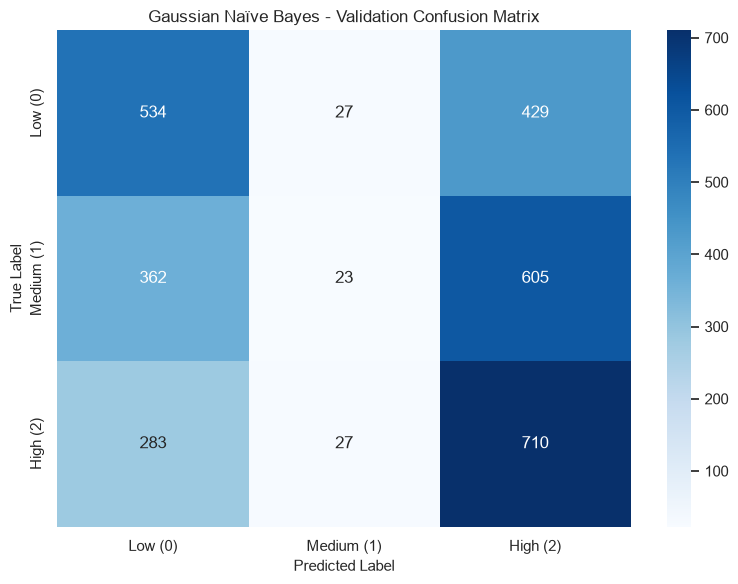

In [5]:
# -------------------------------------------------------------------------
# Visualizing the Confusion Matrix
# -------------------------------------------------------------------------
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=class_names, yticklabels=class_names)
plt.title("Gaussian Naïve Bayes - Validation Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.show()